In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
pd.options.display.float_format = '{:.2f}'.format
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.tree import export_graphviz
from IPython.display import Image
import pydotplus
from six import StringIO

In [2]:
df =pd.read_csv('./Diabetes.csv')
df

,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1354778,0,171,80,34,23,43.51,1.21,21,0
1,1147438,8,92,93,47,36,21.24,0.16,23,0
2,1640031,7,115,47,52,35,41.51,0.08,23,0
3,1883350,9,103,78,25,304,29.58,1.28,43,1
4,1424119,1,85,59,27,35,42.60,0.55,22,0
...,...,...,...,...,...,...,...,...,...,...
9995,1469198,6,95,85,37,267,18.50,0.66,31,0
9996,1432736,0,55,51,7,50,21.87,0.09,34,0
9997,1410962,5,99,59,47,67,30.77,2.30,43,1
9998,1958653,0,145,67,30,21,18.81,0.79,26,0


In [3]:
df.count()

PatientID                 10000
Pregnancies               10000
PlasmaGlucose             10000
DiastolicBloodPressure    10000
TricepsThickness          10000
SerumInsulin              10000
BMI                       10000
DiabetesPedigree          10000
Age                       10000
Diabetic                  10000
dtype: int64

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PatientID               10000 non-null  int64  
 1   Pregnancies             10000 non-null  int64  
 2   PlasmaGlucose           10000 non-null  int64  
 3   DiastolicBloodPressure  10000 non-null  int64  
 4   TricepsThickness        10000 non-null  int64  
 5   SerumInsulin            10000 non-null  int64  
 6   BMI                     10000 non-null  float64
 7   DiabetesPedigree        10000 non-null  float64
 8   Age                     10000 non-null  int64  
 9   Diabetic                10000 non-null  int64  
dtypes: float64(2), int64(8)
memory usage: 781.4 KB


In [5]:
df.describe()

,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,1502122.08,3.26,107.85,71.21,28.82,139.24,31.57,0.40,30.13,0.33
std,289286.76,3.41,31.92,16.80,14.51,133.78,9.80,0.38,12.11,0.47
min,1000038.00,0.00,44.00,24.00,7.00,14.00,18.20,0.08,21.00,0.00
25%,1251672.25,0.00,84.00,58.00,15.00,39.00,21.25,0.14,22.00,0.00
50%,1504394.00,2.00,105.00,72.00,31.00,85.00,31.92,0.20,24.00,0.00
75%,1754607.50,6.00,129.00,85.00,41.00,197.00,39.33,0.62,35.00,1.00
max,1999997.00,14.00,192.00,117.00,92.00,796.00,56.03,2.30,77.00,1.00


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PatientID,10000.00,1502122.08,289286.76,1000038.00,1251672.25,1504394.00,1754607.50,1999997.00
Pregnancies,10000.00,3.26,3.41,0.00,0.00,2.00,6.00,14.00
PlasmaGlucose,10000.00,107.85,31.92,44.00,84.00,105.00,129.00,192.00
DiastolicBloodPressure,10000.00,71.21,16.80,24.00,58.00,72.00,85.00,117.00
TricepsThickness,10000.00,28.82,14.51,7.00,15.00,31.00,41.00,92.00
SerumInsulin,10000.00,139.24,133.78,14.00,39.00,85.00,197.00,796.00
BMI,10000.00,31.57,9.80,18.20,21.25,31.92,39.33,56.03
DiabetesPedigree,10000.00,0.40,0.38,0.08,0.14,0.20,0.62,2.30
Age,10000.00,30.13,12.11,21.00,22.00,24.00,35.00,77.00
Diabetic,10000.00,0.33,0.47,0.00,0.00,0.00,1.00,1.00


In [7]:
row_count =len(df)


In [8]:
print(f'Analyzing {row_count} rows of data')
diabetic_count = df['Diabetic'].value_counts()
print(diabetic_count)

Analyzing 10000 rows of data
Diabetic
0    6656
1    3344
Name: count, dtype: int64


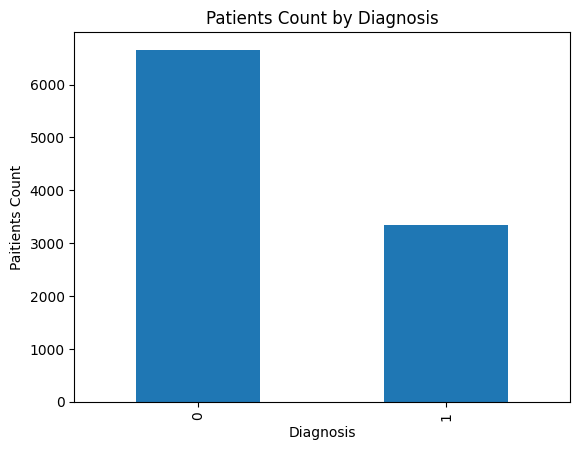

diabetic_count.png saved


In [9]:
fig = plt.figure()
axes = fig.gca()
diabetic_count.plot(kind='bar', ax=axes)
axes.set_title('Patients Count by Diagnosis')
axes.set_xlabel('Diagnosis')
axes.set_ylabel('Paitients Count')
plt.show()
fig.savefig('diabetic_count.png')
print('diabetic_count.png saved')
plt.close(fig)

In [10]:
df.columns

Index(['PatientID', 'Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age',
       'Diabetic'],
      dtype='object')

In [11]:
### Separate Features and Labels
x=df[['Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age']]
y=df['Diabetic']
      

In [12]:
x

,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age
0,0,171,80,34,23,43.51,1.21,21
1,8,92,93,47,36,21.24,0.16,23
2,7,115,47,52,35,41.51,0.08,23
3,9,103,78,25,304,29.58,1.28,43
4,1,85,59,27,35,42.60,0.55,22
...,...,...,...,...,...,...,...,...
9995,6,95,85,37,267,18.50,0.66,31
9996,0,55,51,7,50,21.87,0.09,34
9997,5,99,59,47,67,30.77,2.30,43
9998,0,145,67,30,21,18.81,0.79,26


In [13]:
##Split into train test data set

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [14]:
len(x_train)


7000

In [15]:
len(x_test)

3000

In [16]:
len(y_train)

7000

In [17]:
len(y_test)

3000

In [18]:
diabetic_count =df['Diabetic'].value_counts()
print(diabetic_count)

Diabetic
0    6656
1    3344
Name: count, dtype: int64


In [19]:
### Train the Decision Tree modle
model = DecisionTreeClassifier()  ## Define the model
model.fit(x,y)  ## train the model

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [20]:
y_hat =model.predict(x_test)
print(confusion_matrix(y_test, y_hat))


[[2037    0]
 [   0  963]]


In [21]:
print(classification_report(y_test, y_hat))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2037
           1       1.00      1.00      1.00       963

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



In [22]:
### Prediction inferences

In [23]:
x_new =[[1,91,52,12,135,20.22235558,0.291403522,24],[1,125,83,11,631,26.79889881,0.166820938,58]] # row 1000 and 2002 in csv

actuals = [0,1]

predicted =model.predict(x_new)

for i in range (len(actuals)):
    print("Predicted: %d, Actual: %d" % (predicted[i], actuals[i]))
    print('---'*20)
    


Predicted: 0, Actual: 0
------------------------------------------------------------
Predicted: 1, Actual: 1
------------------------------------------------------------


C:\Ayesha\python\Machine-Learning\Ayesha-Practice\venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [24]:
x_train.columns

Index(['Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age'],
      dtype='object')

In [25]:
%pip install pydotplus

Note: you may need to restart the kernel to use updated packages.


In [30]:
dot_data = StringIO()
#export_graphviz(model, out_file=dot_data, 
  #  filled=True, rounded=True,
  #  special_characters=True)

export_graphviz(model, out_file=dot_data, 
   feature_names=x_train.columns, rounded=True)
graph =pydotplus.graph_from_dot_data(dot_data.getvalue())

In [31]:
Image(graph.create_png())

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.715937 to fit

